# Vietnam Real Estate Listings

Exploratory data analysis of Vietnamese property listings from Hugging Face.

* Data source: https://huggingface.co/datasets/tinixai/vietnam-real-estates
* Team:
* Team members:


**Dataset information**

| Column | Meaning |
|---|---|
| `name` | Listing title |
| `description` | Listing description text |
| `property_type_name` | Property category (apartment, house, land, ...) |
| `province_name` | Province / city |
| `district_name` | District |
| `ward_name` | Ward |
| `street_name` | Street |
| `project_name` | Development project name (if any) |
| `price` | Asking price in VND (`null` if not disclosed) |
| `area` | Floor / land area in m² |
| `floor_count` | Number of floors |
| `frontage_width` | Frontage width (m) |
| `house_depth` | Depth (m) |
| `road_width` | Front road width (m) |
| `bedroom_count` | Number of bedrooms |
| `bathroom_count` | Number of bathrooms |
| `house_direction` | Facing direction |
| `balcony_direction` | Balcony facing direction |
| `published_at` | Listing publish timestamp |


**Research objectives**

1. Profile listing completeness, duplicates, and validity issues across ~3.5M rows.
2. All listings are treated as asking-price market for sale
3. Describe asking-price and price/m² patterns by geography and property type for listings with valid price and area.
4. Quantify numeric associations (Pearson / Spearman) among size, rooms, and asking prices.


## 0. SET UP


In [45]:
%pip install -r requirements.txt


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import numpy as np

# Compat for SciPy + numpy 1.26 (np.long removed; SciPy still references it)
if not hasattr(np, "long"):
    np.long = np.int_
if not hasattr(np, "ulong"):
    np.ulong = np.uint

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

from eda_utils import (
    CATEGORY_COLUMNS,
    EXPECTED_COLUMNS,
    RANDOM_STATE,
    boxplot_stats,
    clean_data,
    group_median_table,
    hist_as_bars,
    pairwise_corr,
    prepare_priced_data,
    print_exclusion_waterfall,
    soft_key_hash,
    title_with_n,
)

np.random.seed(RANDOM_STATE)

pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12


C:\Users\nmqkh\AppData\Local\Temp\ipykernel_8888\555477197.py:4: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "long"):
C:\Users\nmqkh\AppData\Local\Temp\ipykernel_8888\555477197.py:6: FutureWarning: In the future `np.ulong` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "ulong"):


In [47]:
ds = load_dataset("tinixai/vietnam-real-estates")
df = ds["train"].to_pandas()
print("Rows, columns:", df.shape)


Rows, columns: (3500744, 19)


In [48]:
def memory_gb(frame: pd.DataFrame) -> float:
    return frame.memory_usage(deep=True).sum() / (1024 ** 3)

print(f"Memory after load: {memory_gb(df):.3f} GB")

for col in CATEGORY_COLUMNS:
    df[col] = df[col].astype("category")

print(f"Memory after category conversion: {memory_gb(df):.3f} GB")

missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
extra = [c for c in df.columns if c not in EXPECTED_COLUMNS]
assert not missing, f"Missing columns: {missing}"
assert not extra, f"Unexpected columns: {extra}"
assert df.shape[1] == 19, df.shape
print("Schema OK: 19 expected columns present.")
print("dtypes:\n", df.dtypes)
print(df.head())


Memory after load: 6.533 GB
Memory after category conversion: 5.334 GB
Schema OK: 19 expected columns present.
dtypes:
 name                    object
description             object
property_type_name    category
province_name         category
district_name         category
ward_name             category
street_name             object
project_name            object
price                  float64
area                   float64
floor_count            float64
frontage_width         float64
house_depth            float64
road_width             float64
bedroom_count          float64
bathroom_count         float64
house_direction       category
balcony_direction     category
published_at            object
dtype: object
                                                name                                        description  \
0  Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...  - Vị trí siêu đẹp ô tô đỗ cổng, khu vực đang p...   
1  Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...  Nhà 4 tần

## 1. DATA CLEANING

Conservative cleaning: flag issues, keep all rows in `df_clean`, and build `df_priced` as a separate analytical subset.


### 1.1. Initial data inspection


In [50]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.dtypes)
display(df.head())
display(df.describe(include="all"))
print("Non-null counts:\n", df.notna().sum())
for col in ["property_type_name", "province_name", "house_direction", "balcony_direction"]:
    print(f"\n{col} nunique={df[col].nunique(dropna=False)}")


Shape: (3500744, 19)
Columns: ['name', 'description', 'property_type_name', 'province_name', 'district_name', 'ward_name', 'street_name', 'project_name', 'price', 'area', 'floor_count', 'frontage_width', 'house_depth', 'road_width', 'bedroom_count', 'bathroom_count', 'house_direction', 'balcony_direction', 'published_at']
name                    object
description             object
property_type_name    category
province_name         category
district_name         category
ward_name             category
street_name             object
project_name            object
price                  float64
area                   float64
floor_count            float64
frontage_width         float64
house_depth            float64
road_width             float64
bedroom_count          float64
bathroom_count         float64
house_direction       category
balcony_direction     category
published_at            object
dtype: object


,name,description,property_type_name,province_name,district_name,ward_name,street_name,project_name,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,house_direction,balcony_direction,published_at
0,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...","- Vị trí siêu đẹp ô tô đỗ cổng, khu vực đang p...",Nhà,Hà Nội,Bắc Từ Liêm,Phúc Diễn,Ngọa Long,None,7.450000e+09,37.0,NaN,NaN,NaN,NaN,4.0,5.0,NaN,NaN,2025-06-01T05:12:56.941000
1,Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...,Nhà 4 tầng mặt tiền KDC Tạ Quang Bửu P5 Q8. - ...,Nhà,Hồ Chí Minh,8,5,Tạ Quang Bửu,None,9.100000e+09,48.0,4.0,4.0,NaN,NaN,3.0,3.0,NaN,NaN,2025-06-06T04:37:25.903000
2,"Bán biệt thự 300m2 gần sân bóng Bình Minh, đườ...",Bán biệt thự Bình Minh diện tích hơn 300 mét v...,Biệt thự/Nhà liền kề,Vĩnh Long,Bình Minh,NaN,None,None,2.000000e+10,300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-06-15T18:58:07.455000
3,"Cần bán căn hộ CC Thái An, Nguyễn Văn Quá, Q12...","Chung cư Thái An đường Nguyễn Văn Quá, Đông Hư...",Căn hộ chung cư,Hồ Chí Minh,12,Đông Hưng Thuận,Nguyễn Văn Quá,Thái An Apartment,1.300000e+09,44.0,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,2025-06-17T05:32:15.491000
4,"MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ...","MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ...",Nhà,Hồ Chí Minh,Tân Phú,Tân Thành,Nguyễn Hậu,None,9.000000e+09,60.0,NaN,NaN,NaN,NaN,2.0,3.0,NaN,NaN,2025-06-06T04:06:17.378000


,name,description,property_type_name,province_name,district_name,ward_name,street_name,project_name,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,house_direction,balcony_direction,published_at
count,3500744,3500744,3500744,3500744,3398811,3004028,2123884,1000853,3.282250e+06,3.500740e+06,808762.000000,1.774320e+06,68456.000000,669871.000000,1.900383e+06,1.779770e+06,1086530,567402,3500744
unique,2539381,3041712,5,63,626,4416,10200,5092,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,16,3497379
top,,,Nhà,Hồ Chí Minh,Thủ Đức,12,Lạc Long Quân,Vinhomes Ocean Park 2 – The Empire,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Đông Nam,Đông Nam,2026-03-21T00:00:01
freq,1868,1868,1575536,1357526,225314,43474,23387,19871,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,145317,85314,91
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.958440e+10,5.050264e+02,3.853717,2.731670e+01,23.988374,9.571250,3.373194e+00,3.130349e+00,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.486320e+13,9.726008e+04,1.753971,1.077600e+04,94.980395,132.991368,2.713995e+00,2.670448e+00,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,1.000000e+00,1.000000,3.800000e-01,1.000000,0.500000,1.000000e+00,1.000000e+00,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000e+09,5.600000e+01,3.000000,4.200000e+00,13.500000,4.000000,2.000000e+00,2.000000e+00,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.300000e+09,8.000000e+01,4.000000,5.000000e+00,18.720000,6.000000,3.000000e+00,2.000000e+00,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.400000e+10,1.200000e+02,5.000000,7.500000e+00,24.600000,10.000000,4.000000e+00,4.000000e+00,NaN,NaN,NaN


Non-null counts:
 name                  3500744
description           3500744
property_type_name    3500744
province_name         3500744
district_name         3398811
ward_name             3004028
street_name           2123884
project_name          1000853
price                 3282250
area                  3500740
floor_count            808762
frontage_width        1774320
house_depth             68456
road_width             669871
bedroom_count         1900383
bathroom_count        1779770
house_direction       1086530
balcony_direction      567402
published_at          3500744
dtype: int64

property_type_name nunique=5

province_name nunique=63

house_direction nunique=32

balcony_direction nunique=17


### 1.2. Missing value analysis

Missing `price` means the asking price was not disclosed. Missing `project_name` often means the listing is not in a named project. Missing directions and dimensions mean the listing did not provide that detail. Rows with missing values are retained.


,n_missing,pct
name,0,0.000000
province_name,0,0.000000
published_at,0,0.000000
description,0,0.000000
property_type_name,0,0.000000
area,4,0.000114
district_name,101933,2.911752
price,218494,6.241359
ward_name,496716,14.188870
street_name,1376860,39.330497


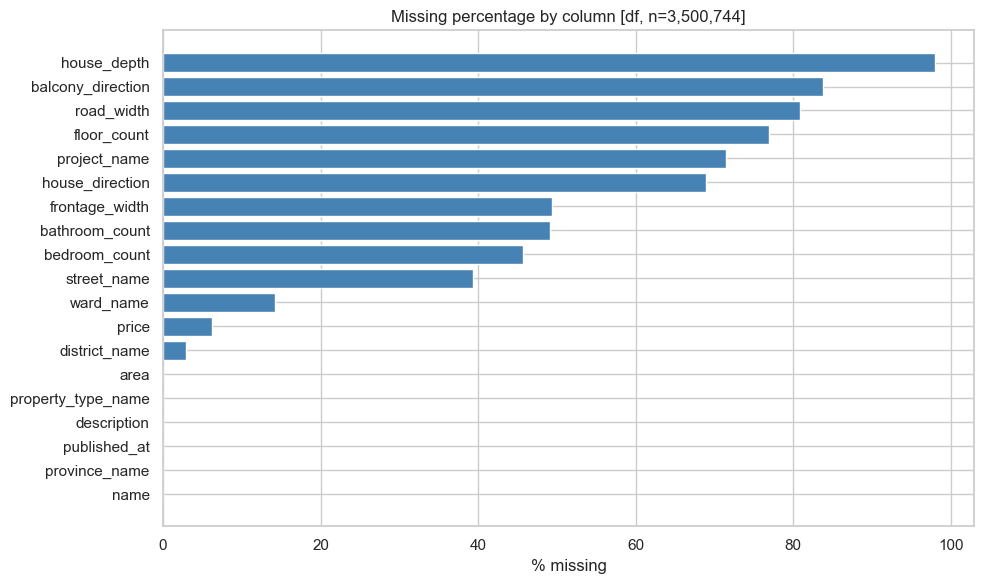

In [51]:
miss = df.isna().sum().rename("n_missing").to_frame()
miss["pct"] = 100 * miss["n_missing"] / len(df)
miss = miss.sort_values("pct", ascending=True)
display(miss)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(miss.index.astype(str), miss["pct"], color="steelblue")
ax.set_xlabel("% missing")
ax.set_title(title_with_n("Missing percentage by column", "df", len(df)))
plt.tight_layout()
plt.show()


In [52]:
top_types = df["property_type_name"].value_counts().head(10).index
sub = df[df["property_type_name"].isin(top_types)]
miss_by_type = (
    sub.groupby("property_type_name", observed=True)[
        ["project_name", "frontage_width", "road_width", "bedroom_count"]
    ]
    .apply(lambda x: x.isna().mean())
    .reindex(top_types)
)
print(title_with_n("Null rates by property_type_name (top 10)", "df", len(df)))
display(miss_by_type.map(lambda x: f"{x:.1%}"))

Null rates by property_type_name (top 10) [df, n=3,500,744]


,project_name,frontage_width,road_width,bedroom_count
property_type_name,,,,
Nhà,98.2%,39.0%,78.5%,34.9%
Đất,93.5%,27.2%,70.9%,99.9%
Căn hộ chung cư,12.5%,99.9%,100.0%,6.9%
Biệt thự/Nhà liền kề,27.2%,36.7%,72.7%,48.5%
Shophouse,9.2%,40.6%,73.9%,58.7%


### 1.3. Duplicate analysis

Exact and soft duplicates are reported only. Nothing is deleted.


In [53]:
exact_dup = df.duplicated(subset=EXPECTED_COLUMNS, keep="first")
soft_dup = soft_key_hash(df).duplicated(keep="first")
print(f"Exact duplicates (keep=first): {exact_dup.sum():,} ({exact_dup.mean():.2%})")
print(f"Soft duplicates (keep=first): {soft_dup.sum():,} ({soft_dup.mean():.2%})")


Exact duplicates (keep=first): 50 (0.00%)
Soft duplicates (keep=first): 865,362 (24.72%)


### 1.4. Data type validation and geography / direction checks


In [54]:
numeric_cols = [
    "price", "area", "floor_count", "frontage_width", "house_depth",
    "road_width", "bedroom_count", "bathroom_count",
]
print(df[numeric_cols].dtypes)
pub = pd.to_datetime(df["published_at"], errors="coerce")
print("published_at parse nulls:", int(pub.isna().sum()))
print("published_at min/max:", pub.min(), pub.max())
now = pd.Timestamp.utcnow().tz_localize(None)
pub_naive = pub.dt.tz_localize(None) if pub.dt.tz is not None else pub
print("published_at later than notebook run timestamp:", int((pub_naive > now).sum()))


price             float64
area              float64
floor_count       float64
frontage_width    float64
house_depth       float64
road_width        float64
bedroom_count     float64
bathroom_count    float64
dtype: object
published_at parse nulls: 22024
published_at min/max: 2025-06-01 00:01:38.762000 2026-03-30 23:59:56.217000
published_at later than notebook run timestamp: 0


In [55]:
print("province nunique:", df["province_name"].nunique(dropna=False))
print("district nunique:", df["district_name"].nunique(dropna=False))
print("Top 20 provinces:\n", df["province_name"].value_counts().head(20))
dist_prov = (
    df.dropna(subset=["district_name"])
    .groupby("district_name", observed=True)["province_name"]
    .nunique()
)
print("district_name values spanning >1 province:", int((dist_prov > 1).sum()))


province nunique: 63
district nunique: 627
Top 20 provinces:
 province_name
Hồ Chí Minh          1357526
Hà Nội               1140542
Đà Nẵng               185973
Bình Dương            150377
Khánh Hòa              98377
Hải Phòng              72788
Hưng Yên               65223
Đồng Nai               59543
Long An                47125
Bà Rịa - Vũng Tàu      45885
Lâm Đồng               26007
Quảng Ninh             20532
Bắc Ninh               20434
Quảng Nam              19997
Hòa Bình               13373
Thanh Hóa              11186
Hà Nam                 11111
Vĩnh Phúc              10803
Huế                    10118
Tây Ninh                9292
Name: count, dtype: int64
district_name values spanning >1 province: 15


In [56]:
print(title_with_n("house_direction value counts", "df", len(df)))
display(df["house_direction"].value_counts(dropna=False))
print(title_with_n("balcony_direction value counts", "df", len(df)))
display(df["balcony_direction"].value_counts(dropna=False))


house_direction value counts [df, n=3,500,744]


house_direction
NaN                                2414214
Đông Nam                            145317
Nam                                 118194
Đông                                105773
Đông - Nam                          100556
Tây Bắc                              99547
Đông Bắc                             92433
Bắc                                  83539
Tây Nam                              79100
Tây - Bắc                            73043
Tây                                  70330
Đông - Bắc                           64063
Tây - Nam                            54599
Đông, Nam                                5
Đông, Bắc                                5
Tây, Đông Bắc, Tây Nam, Tây Bắc          4
Đông, Đông Nam, Nam, Bắc                 4
Đông Nam, Tây Bắc                        3
Bắc, Tây                                 2
Đông, Đông Nam, Bắc                      1
Đông, Tây Nam                            1
Đông, Tây                                1
Đông Nam, Đông Bắc                    

balcony_direction value counts [df, n=3,500,744]


balcony_direction
NaN                                2933342
Đông Nam                             85314
Đông - Nam                           78628
Nam                                  61650
Đông                                 45675
Đông Bắc                             44389
Tây Bắc                              40810
Bắc                                  40241
Đông - Bắc                           39020
Tây Nam                              35939
Tây - Bắc                            35747
Tây - Nam                            31179
Tây                                  28801
Đông, Đông Nam, Nam, Bắc                 4
Đông - Bắc, Đông - Nam                   2
Tây, Đông Bắc, Tây Nam, Tây Bắc          2
Tây - Bắc, Đông - Nam                    1
Name: count, dtype: int64

### 1.5. Validity and anomaly investigation

Flags only — no automatic removal of extremes.


In [57]:
print("Nonpositive price:", int((df["price"] <= 0).sum()), "| null price:", int(df["price"].isna().sum()))
print("Nonpositive area:", int((df["area"] <= 0).sum()), "| null area:", int(df["area"].isna().sum()))
for c in ["floor_count", "bedroom_count", "bathroom_count"]:
    print(f"Negative {c}:", int((df[c] < 0).sum()))


Nonpositive price: 57320 | null price: 218494
Nonpositive area: 0 | null area: 4
Negative floor_count: 0
Negative bedroom_count: 0
Negative bathroom_count: 0


### 1.6. Cleaning and analytical dataset creation

Derived columns added to `df_clean` (all 19 originals retained):

| Column | Definition |
|---|---|
| `is_exact_dup` | Exact duplicate over the 19 original columns |
| `is_soft_dup` | Soft-key duplicate |
| `flag_nonpositive_price` | `price <= 0` (null → False) |
| `flag_nonpositive_area` | `area <= 0` (null → False) |
| `flag_negative_floor_count` | `floor_count < 0` |
| `flag_negative_bedroom_count` | `bedroom_count < 0` |
| `flag_negative_bathroom_count` | `bathroom_count < 0` |
| `flag_extreme_area` | `area` above 99.9th pct of positive areas |
| `flag_extreme_floor_count` | above 99.9th pct of non-negative values |
| `flag_extreme_bedroom_count` | above 99.9th pct of non-negative values |
| `flag_extreme_bathroom_count` | above 99.9th pct of non-negative values |

`df_priced` keeps listings with `price > 0` and `area > 0` (sale-market assumption), and adds `price_per_m2` and `flag_extreme_price_per_m2` only.


In [58]:
df_clean = clean_data(df)
df_priced = prepare_priced_data(df_clean)
print("df:", df.shape, "| df_clean:", df_clean.shape, "| df_priced:", df_priced.shape)
assert len(df_clean) == len(df)
assert df_clean.index.equals(df.index)
assert "price_per_m2" not in df_clean.columns
assert "price_per_m2" in df_priced.columns
print_exclusion_waterfall(df, df_clean, df_priced)


df: (3500744, 19) | df_clean: (3500744, 30) | df_priced: (3224930, 32)
Exclusion waterfall
  df rows: 3,500,744 (excluded 0, 0.00%)
  df_clean rows: 3,500,744 (excluded 0, 0.00%)
  after exclude missing/nonpositive price: 3,224,930 (excluded 275,814, 7.88%)
  after exclude missing/nonpositive area / df_priced: 3,224,930 (excluded 0, 0.00%)


In [59]:
print(f"df_priced size: {len(df_priced):,} ({len(df_priced) / len(df_clean):.2%} of df_clean)")
if len(df_priced):
    low = (df_priced["price"] < 10_000_000).mean()
    print(f"Share of df_priced rows with price < 10,000,000 VND: {low:.2%}")
    print("df_priced price percentiles (1, 50, 99):")
    print(df_priced["price"].quantile([0.01, 0.50, 0.99]))


df_priced size: 3,224,930 (92.12% of df_clean)
Share of df_priced rows with price < 10,000,000 VND: 0.01%
df_priced price percentiles (1, 50, 99):
0.01    5.900000e+08
0.50    7.500000e+09
0.99    1.390000e+11
Name: price, dtype: float64


#### Soft-duplicate clusters and extreme tails


In [60]:
sk = soft_key_hash(df_clean)
cluster_sizes = sk.value_counts()
soft_clusters = cluster_sizes[cluster_sizes > 1].head(10)
print(title_with_n("10 largest soft-duplicate clusters", "df_clean", len(df_clean)))
display(soft_clusters.rename("cluster_size").to_frame())
print(f"Exact dup share: {df_clean['is_exact_dup'].mean():.2%}")
print(f"Soft dup share: {df_clean['is_soft_dup'].mean():.2%}")


10 largest soft-duplicate clusters [df_clean, n=3,500,744]


,cluster_size
14133054121955044176,121
13396537198429708950,81
16691324701128384324,79
9646511522010444815,75
9456638442733968437,68
17208016835494765349,68
191791319593057052,67
15682930743098231210,66
14118773797077778614,62
11354715444241774349,60


Exact dup share: 0.02%
Soft dup share: 24.72%


In [61]:
sale_eligible = df_priced.copy()

for col in ["area", "price_per_m2"]:
    q = sale_eligible[col].quantile([0.01, 0.99, 0.999])
    print(f"{col} percentiles 1/99/99.9:\n", q)
    lo, hi = q.loc[0.01], q.loc[0.999]
    below = sale_eligible[sale_eligible[col] < lo]
    above = sale_eligible[sale_eligible[col] > hi]
    cols_show = ["name", "province_name", "price", "area", "price_per_m2"]
    print(f"5 random rows below 1st pct ({col}):")
    display(below.sample(n=min(5, len(below)), random_state=RANDOM_STATE)[cols_show])
    print(f"5 random rows above 99.9th pct ({col}):")
    display(above.sample(n=min(5, len(above)), random_state=RANDOM_STATE)[cols_show])


area percentiles 1/99/99.9:
 0.010       25.0
0.990     2119.0
0.999    23000.0
Name: area, dtype: float64
5 random rows below 1st pct (area):


,name,province_name,price,area,price_per_m2
2879237,"Bán nhà mới 3.55 tỷ, kế bên xe hơi, Đoàn Văn B...",Hồ Chí Minh,3.550000e+09,21.0,1.690476e+08
2831798,Bán nhà Quận 10 giá 6 tỷ nhỉnh hẻm xe tải thôn...,Hồ Chí Minh,6.800000e+09,24.0,2.833333e+08
3306637,Nhà 3 Tầng Mỗi Phòng Đều Có Ban Công& Wc Riêng...,Hồ Chí Minh,3.300000e+09,20.0,1.650000e+08
3241890,"Bán gấp NR 3PN, 4WC tại Tam Khương, 3,95 tỷ, 17m2",Hà Nội,3.950000e+09,17.0,2.323529e+08
1446411,"Bán nhà riêng tại Trần Đình Xu, Cầu Kho, Quận ...",Hồ Chí Minh,5.700000e+09,21.0,2.714286e+08


5 random rows above 99.9th pct (area):


,name,province_name,price,area,price_per_m2
2561625,Mảnh đất vườn điều 80m mặt tiền bê tông gần ch...,Bình Phước,1.500000e+09,28000.0,5.357143e+04
989235,"Bán đất tại Nhơn Ninh, Tân Thạnh, Long An, giá...",Long An,2.720000e+10,28507.0,9.541516e+05
612403,"Bán gấp 9ha đất tràm Tân Hòa, Tây Ninh - Giá đ...",Tây Ninh,1.600000e+09,90000.0,1.777778e+04
2578843,Siêu VIP ngọn đồi view 360 cách sân bay Đà Lạt...,Lâm Đồng,5.500000e+10,25000.0,2.200000e+06
2593468,"Chuyển nhượng dự án biển - Quan Lạn, Vân Đồn, ...",Quảng Ninh,4.300000e+11,736000.0,5.842391e+05


price_per_m2 percentiles 1/99/99.9:
 0.010    1.900000e+06
0.990    6.076923e+08
0.999    1.189036e+09
Name: price_per_m2, dtype: float64
5 random rows below 1st pct (price_per_m2):


,name,province_name,price,area,price_per_m2
618205,Đất mặt tiền đường lớn kích thước đẹp thích hợ...,Long An,9.000000e+08,1000.0,9.000000e+05
2583845,"Rời phố về vườn - 1,8 sào đất xinh cận kề Lý T...",Bình Thuận,2.000000e+09,1812.6,1.103387e+06
789356,Bán gấp mảnh vườn 1.080m² gần hồ Trị An Định Q...,Đồng Nai,9.180000e+08,1080.0,8.500000e+05
2421462,"Đất mặt tiền đường nhựa 7m liên xã Sơn Bình, C...",Bà Rịa - Vũng Tàu,2.050000e+09,3078.0,6.660169e+05
1782483,"Bán đất Định An 1 sào, mặt tiền 9m, gần đường ...",Hồ Chí Minh,3.990000e+08,1080.0,3.694444e+05


5 random rows above 99.9th pct (price_per_m2):


,name,province_name,price,area,price_per_m2
1492409,"MP cổ Hàng Gai, vị trí kim cương, full thổ cư,...",Hà Nội,2.850000e+11,218.00,1.307339e+09
199350,Phố hàng cót + phố phùng hưng - nhà lợi thế ha...,Hà Nội,1.700000e+11,141.00,1.205674e+09
1432171,Khách sạn Kin Hotel 68 phòng trái tim phố Nhật...,Hồ Chí Minh,5.000000e+11,227.20,2.200704e+09
229239,"Toà nhà mặt phố Xuân Diệu 305 Tỷ 250m2,9 tầng ...",Hà Nội,3.050000e+11,250.00,1.220000e+09
107260,"Bán tòa nhà MP 19 - 21 - 23 Mạc Đỉnh Chi, P. Đ...",Hồ Chí Minh,2.500000e+11,198.27,1.260907e+09


End of cleaning. `df` is unchanged after category conversion; `df_clean` retains every row; `df_priced` is the price-analysis subset.


## 2. EXPLORATORY DATA ANALYSIS

All listings are treated as for sale. Price-specific figures use `df_priced` (positive price and area) unless noted. Group statistics require **n ≥ 100**.


### 2.1. General dataset profile


In [62]:
profile = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "non_null": df_clean.notna().sum(),
    "null_pct": 100 * df_clean.isna().mean(),
    "nunique": df_clean.nunique(dropna=True),
})
display(profile)
display(df_clean[numeric_cols].describe())
print(title_with_n("Profile complete", "df_clean", len(df_clean)))


,dtype,non_null,null_pct,nunique
name,object,3500744,0.000000,2539381
description,object,3500744,0.000000,3041712
property_type_name,category,3500744,0.000000,5
province_name,category,3500744,0.000000,63
district_name,category,3398811,2.911752,626
ward_name,category,3004028,14.188870,4416
street_name,object,2123884,39.330497,10200
project_name,object,1000853,71.410277,5092
price,float64,3282250,6.241359,34132
area,float64,3500740,0.000114,24525


,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count
count,3.282250e+06,3.500740e+06,808762.000000,1.774320e+06,68456.000000,669871.000000,1.900383e+06,1.779770e+06
mean,2.958440e+10,5.050264e+02,3.853717,2.731670e+01,23.988374,9.571250,3.373194e+00,3.130349e+00
std,1.486320e+13,9.726008e+04,1.753971,1.077600e+04,94.980395,132.991368,2.713995e+00,2.670448e+00
min,0.000000e+00,1.000000e+00,1.000000,3.800000e-01,1.000000,0.500000,1.000000e+00,1.000000e+00
25%,4.000000e+09,5.600000e+01,3.000000,4.200000e+00,13.500000,4.000000,2.000000e+00,2.000000e+00
50%,7.300000e+09,8.000000e+01,4.000000,5.000000e+00,18.720000,6.000000,3.000000e+00,2.000000e+00
75%,1.400000e+10,1.200000e+02,5.000000,7.500000e+00,24.600000,10.000000,4.000000e+00,4.000000e+00
max,2.659719e+16,8.200000e+07,255.000000,9.080000e+06,15380.000000,103000.000000,2.000000e+02,2.550000e+02


Profile complete [df_clean, n=3,500,744]


### 2.2. Price distributions


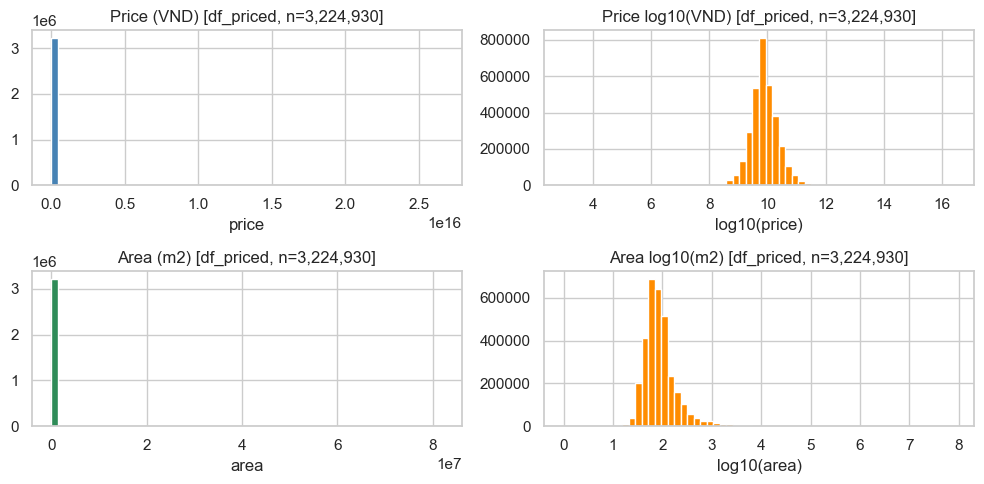

In [92]:
fig, axes = plt.subplots(2, 2)

hist_as_bars(axes[0][0], df_priced["price"], bins=60, color="steelblue")
axes[0][0].set_title(title_with_n("Price (VND)", "df_priced", len(df_priced)))
axes[0][0].set_xlabel("price")

hist_as_bars(axes[0][1], df_priced["price"], bins=60, log_x=True, color="darkorange")
axes[0][1].set_title(title_with_n("Price log10(VND)", "df_priced", len(df_priced)))
axes[0][1].set_xlabel("log10(price)")

hist_as_bars(axes[1][0], df_priced["area"], bins=60, color="seagreen")
axes[1][0].set_title(title_with_n("Area (m2)", "df_priced", len(df_priced)))
axes[1][0].set_xlabel("area")

hist_as_bars(axes[1][1], df_priced["area"], bins=60, log_x=True, color="darkorange")
axes[1][1].set_title(title_with_n("Area log10(m2)", "df_priced", len(df_priced)))
axes[1][1].set_xlabel("log10(area)")

plt.tight_layout()
plt.show()

### 2.3. Property type and Geographical analysis


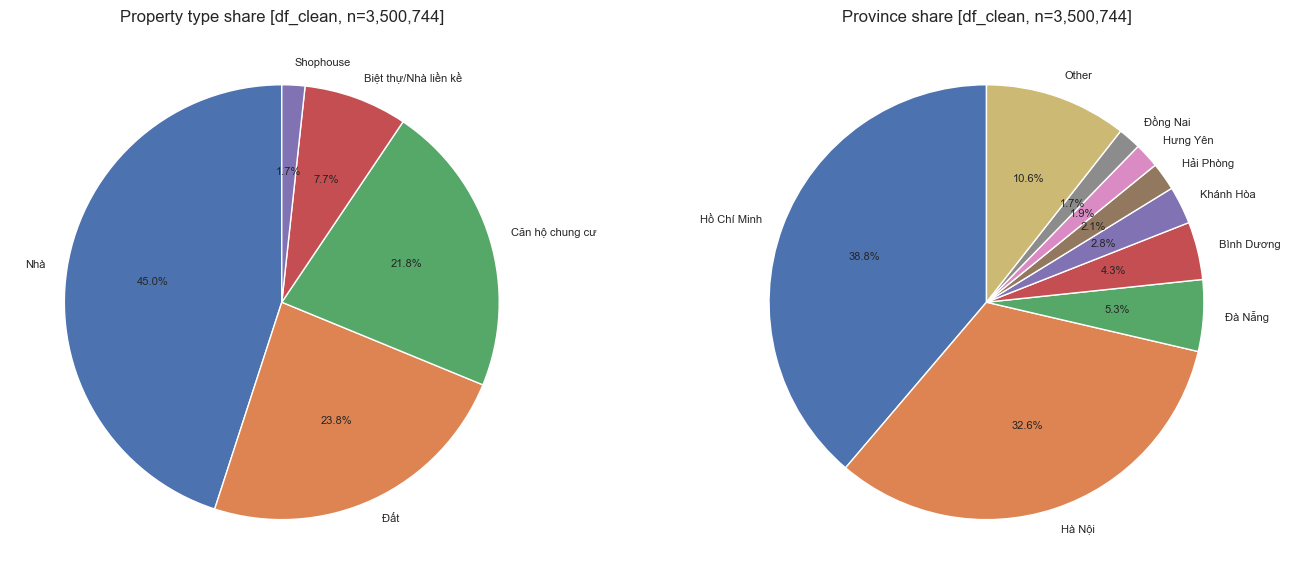

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, col, top_n, title in [
    (axes[0], "property_type_name", 8, "Property type share"),
    (axes[1], "province_name", 8, "Province share"),
]:
    counts = df_clean[col].value_counts(dropna=False)
    top = counts.head(top_n)
    other = counts.iloc[top_n:].sum()
    if other > 0:
        top = pd.concat([top, pd.Series({"Other": other})])

    ax.pie(
        top.values,
        labels=top.index.astype(str),
        autopct="%1.1f%%",
        startangle=90,
        textprops={"fontsize": 8},
    )
    ax.set_title(title_with_n(title, "df_clean", len(df_clean)))

plt.tight_layout()
plt.show()

In [96]:
prov_price = group_median_table(df_priced, "province_name", "price", min_n=100)
prov_ppm2 = group_median_table(df_priced, "province_name", "price_per_m2", min_n=100)
print(title_with_n("Median asking price by province", "df_priced", len(df_priced)))
display(prov_price.head(15))
print(title_with_n("Median price_per_m2 by province", "df_priced", len(df_priced)))
display(prov_ppm2.head(15))


Median asking price by province [df_priced, n=3,224,930]


,province_name,n,median
25,Hồ Chí Minh,1279090,7.700000e+09
18,Hà Nội,1035822,9.620000e+09
58,Đà Nẵng,167878,8.000000e+09
2,Bình Dương,138995,2.915000e+09
26,Khánh Hòa,94320,4.900000e+09
23,Hải Phòng,66179,3.850000e+09
21,Hưng Yên,57181,7.600000e+09
61,Đồng Nai,55053,2.750000e+09
1,Bà Rịa - Vũng Tàu,43941,3.950000e+09
30,Long An,42963,2.200000e+09


Median price_per_m2 by province [df_priced, n=3,224,930]


,province_name,n,median
25,Hồ Chí Minh,1279090,1.087912e+08
18,Hà Nội,1035822,1.875000e+08
58,Đà Nẵng,167878,7.850000e+07
2,Bình Dương,138995,3.757022e+07
26,Khánh Hòa,94320,5.389831e+07
23,Hải Phòng,66179,5.072464e+07
21,Hưng Yên,57181,8.459870e+07
61,Đồng Nai,55053,2.055556e+07
1,Bà Rịa - Vũng Tàu,43941,2.550000e+07
30,Long An,42963,2.109375e+07


In [69]:
dist_price = group_median_table(df_priced, "district_name", "price", min_n=100, top_n=15)
dist_ppm2 = group_median_table(df_priced, "district_name", "price_per_m2", min_n=100, top_n=15)
print(title_with_n("Median price by district (top 15 by n)", "df_priced", len(df_priced)))
display(dist_price)
print(title_with_n("Median price_per_m2 by district (top 15 by n)", "df_priced", len(df_priced)))
display(dist_ppm2)


Median price by district (top 15 by n) [df_priced, n=3,224,930]


,district_name,n,median
454,Thủ Đức,218001,8.000000e+09
8,7,105033,7.700000e+09
114,Cầu Giấy,104511,1.400000e+10
173,Hà Đông,102460,9.300000e+09
155,Gò Vấp,95637,7.900000e+09
301,Nam Từ Liêm,93555,8.500000e+09
40,Bình Thạnh,92384,1.019000e+10
246,Long Biên,88140,1.120000e+10
490,Tân Bình,87020,9.000000e+09
497,Tân Phú,80767,7.300000e+09


Median price_per_m2 by district (top 15 by n) [df_priced, n=3,224,930]


,district_name,n,median
454,Thủ Đức,218001,9.022556e+07
8,7,105033,9.793814e+07
114,Cầu Giấy,104511,2.557143e+08
173,Hà Đông,102460,1.944444e+08
155,Gò Vấp,95637,1.227390e+08
301,Nam Từ Liêm,93555,1.375000e+08
40,Bình Thạnh,92384,1.541667e+08
246,Long Biên,88140,2.030152e+08
490,Tân Bình,87020,1.450000e+08
497,Tân Phú,80767,1.090909e+08


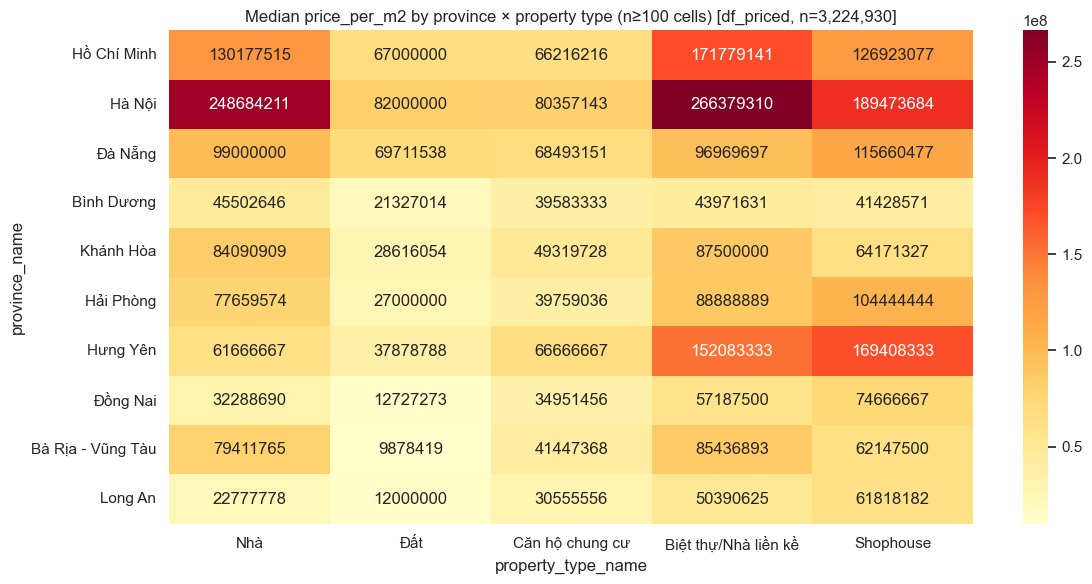

In [70]:
top_prov = df_priced["province_name"].value_counts().head(10).index
top_types = df_priced["property_type_name"].value_counts().head(5).index
sub = df_priced[
    df_priced["province_name"].isin(top_prov)
    & df_priced["property_type_name"].isin(top_types)
]
cell_stats = (
    sub.groupby(["province_name", "property_type_name"], observed=True)["price_per_m2"]
    .agg(n="size", median="median")
    .reset_index()
)
cell_stats = cell_stats[cell_stats["n"] >= 100]
heat = cell_stats.pivot(index="province_name", columns="property_type_name", values="median")
heat = heat.reindex(index=top_prov, columns=top_types)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax)
ax.set_title(title_with_n(
    "Median price_per_m2 by province × property type (n≥100 cells)",
    "df_priced",
    len(df_priced),
))
plt.tight_layout()
plt.show()


### 2.4. Area–price relationships


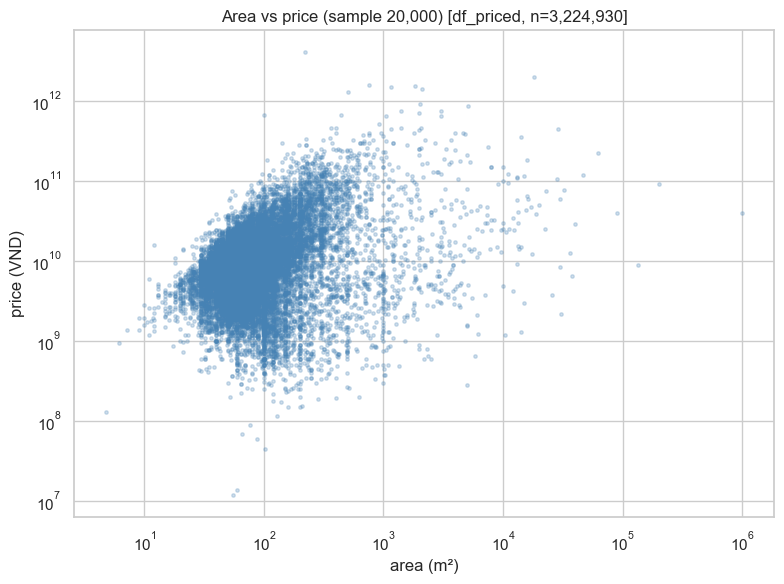

In [71]:
scatter_n = min(20_000, len(df_priced))
scatter_df = df_priced.sample(n=scatter_n, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scatter_df["area"], scatter_df["price"], s=6, alpha=0.25, c="steelblue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("area (m²)")
ax.set_ylabel("price (VND)")
ax.set_title(title_with_n(f"Area vs price (sample {scatter_n:,})", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


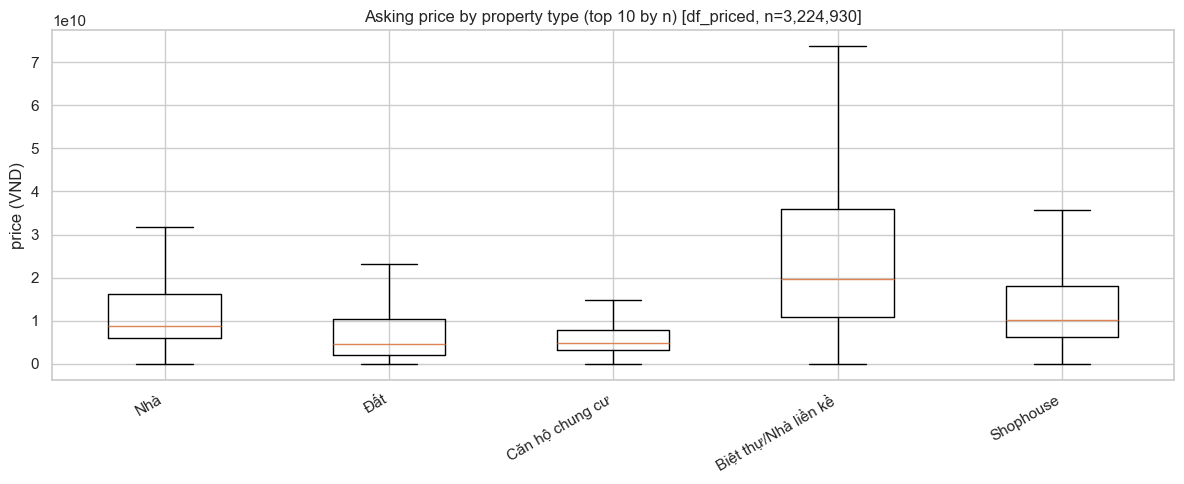

In [72]:
top_types10 = df_priced["property_type_name"].value_counts().head(10).index.tolist()
stats = boxplot_stats(df_priced, "property_type_name", "price", top_types10)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bxp(stats, showfliers=False)
ax.set_xticklabels([s["label"] for s in stats], rotation=30, ha="right")
ax.set_ylabel("price (VND)")
ax.set_title(title_with_n("Asking price by property type (top 10 by n)", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


### 2.5. Price per square meter analysis


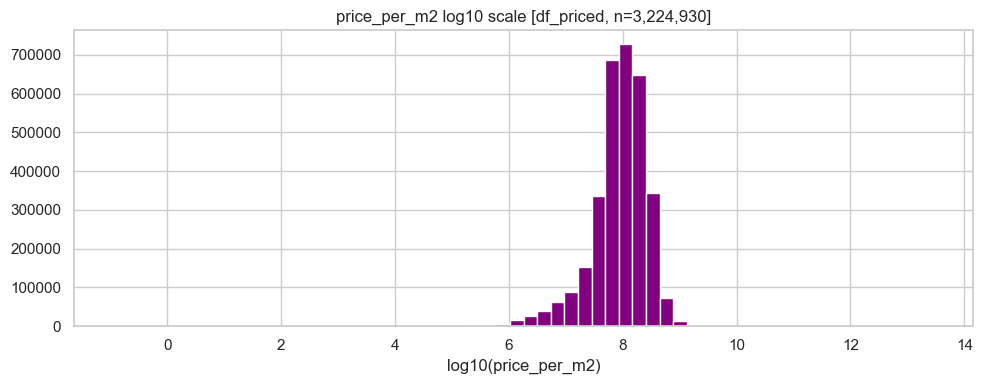

In [73]:
fig, ax = plt.subplots(figsize=(10, 4))
hist_as_bars(ax, df_priced["price_per_m2"], bins=60, log_x=True, color="purple")
ax.set_title(title_with_n("price_per_m2 log10 scale", "df_priced", len(df_priced)))
ax.set_xlabel("log10(price_per_m2)")
plt.tight_layout()
plt.show()


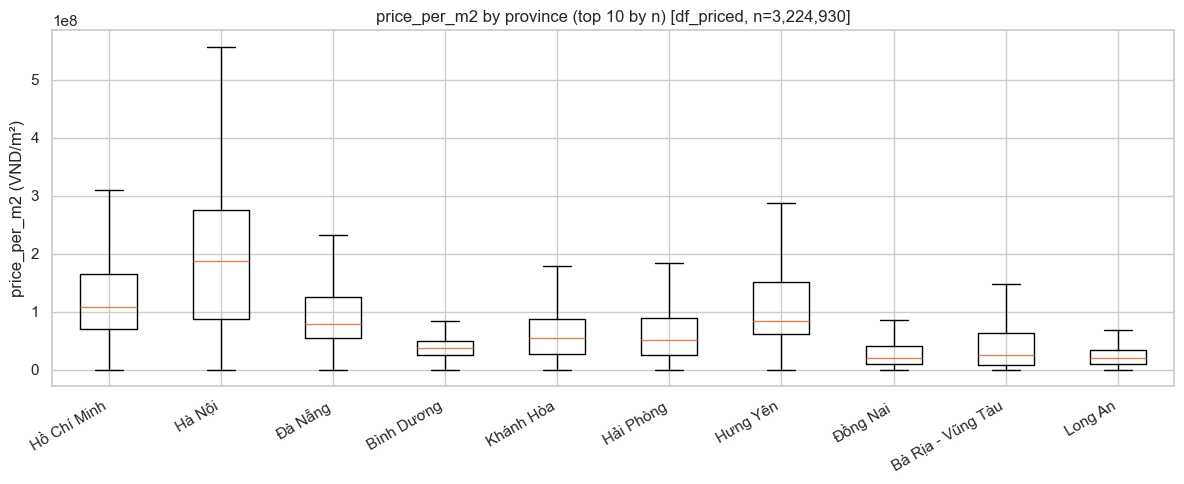

In [74]:
top_prov10 = df_priced["province_name"].value_counts().head(10).index.tolist()
stats = boxplot_stats(df_priced, "province_name", "price_per_m2", top_prov10)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bxp(stats, showfliers=False)
ax.set_xticklabels([s["label"] for s in stats], rotation=30, ha="right")
ax.set_ylabel("price_per_m2 (VND/m²)")
ax.set_title(title_with_n("price_per_m2 by province (top 10 by n)", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


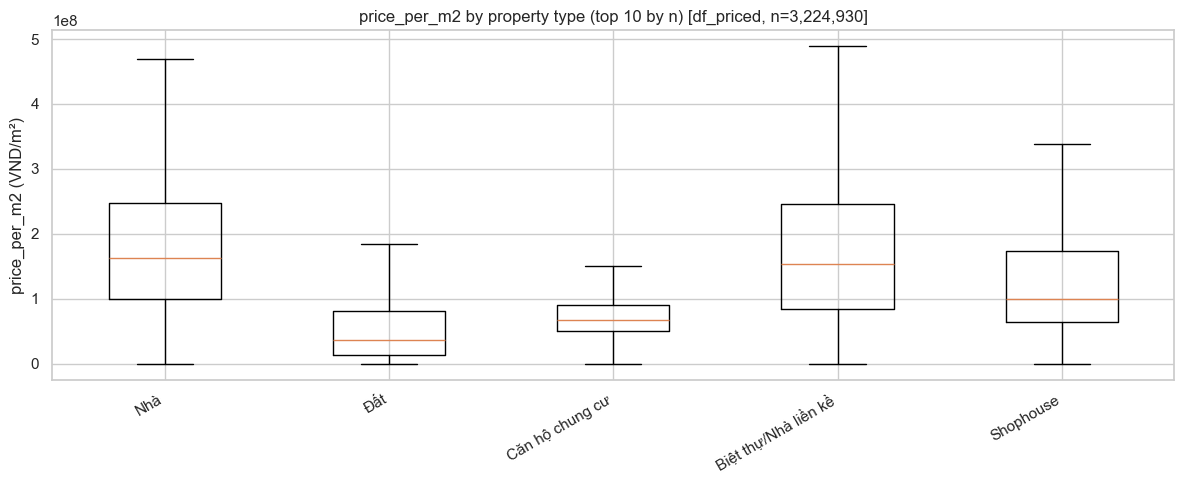

In [75]:
stats = boxplot_stats(df_priced, "property_type_name", "price_per_m2", top_types10)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bxp(stats, showfliers=False)
ax.set_xticklabels([s["label"] for s in stats], rotation=30, ha="right")
ax.set_ylabel("price_per_m2 (VND/m²)")
ax.set_title(title_with_n("price_per_m2 by property type (top 10 by n)", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


### 2.6. Correlation analysis

Pearson and Spearman with pairwise deletion on `df_priced`. Pairs with n < 1,000 are not reported.


In [76]:
CORR_COLS = [
    "price", "price_per_m2", "area", "floor_count", "frontage_width",
    "house_depth", "road_width", "bedroom_count", "bathroom_count",
]
extreme_flags = [c for c in df_priced.columns if c.startswith("flag_extreme_")]
df_priced_no_ext = df_priced.loc[~df_priced[extreme_flags].any(axis=1)]

pearson1, n1 = pairwise_corr(df_priced, CORR_COLS, method="pearson")
spearman1, _ = pairwise_corr(df_priced, CORR_COLS, method="spearman")
pearson2, n2 = pairwise_corr(df_priced_no_ext, CORR_COLS, method="pearson")
spearman2, _ = pairwise_corr(df_priced_no_ext, CORR_COLS, method="spearman")

print(title_with_n("Pairwise n (run 1: all df_priced)", "df_priced", len(df_priced)))
display(n1.astype(int))
print("Pairs with n < 1000 are NaN (not reported) in correlation matrices.")


Pairwise n (run 1: all df_priced) [df_priced, n=3,224,930]


,price,price_per_m2,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count
price,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
price_per_m2,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
area,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
floor_count,742742,742742,742742,742742,517653,17799,358196,594050,548209
frontage_width,1662052,1662052,1662052,517653,1662052,59469,548138,790254,746294
house_depth,59487,59487,59487,17799,59469,59487,210,17264,13504
road_width,614511,614511,614511,358196,548138,210,614511,347100,330043
bedroom_count,1749076,1749076,1749076,594050,790254,17264,347100,1749076,1602003
bathroom_count,1636582,1636582,1636582,548209,746294,13504,330043,1602003,1636582


Pairs with n < 1000 are NaN (not reported) in correlation matrices.


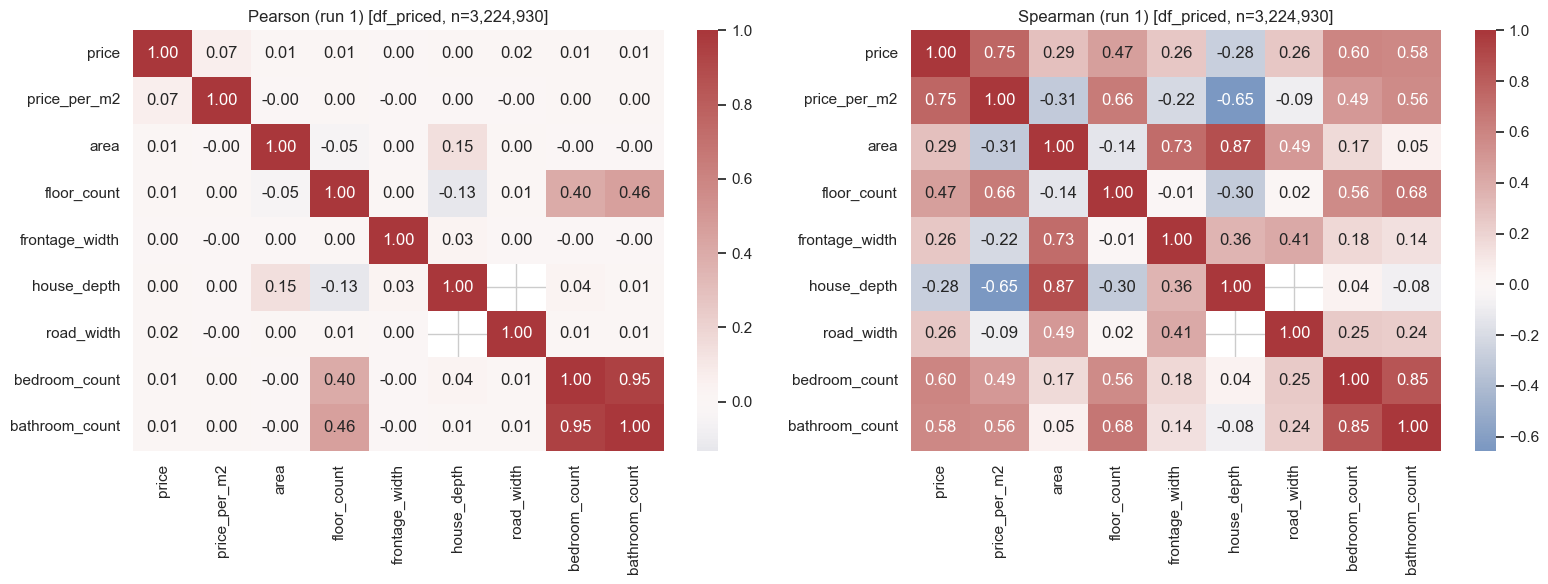

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson1.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title(title_with_n("Pearson (run 1)", "df_priced", len(df_priced)))
sns.heatmap(spearman1.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title(title_with_n("Spearman (run 1)", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


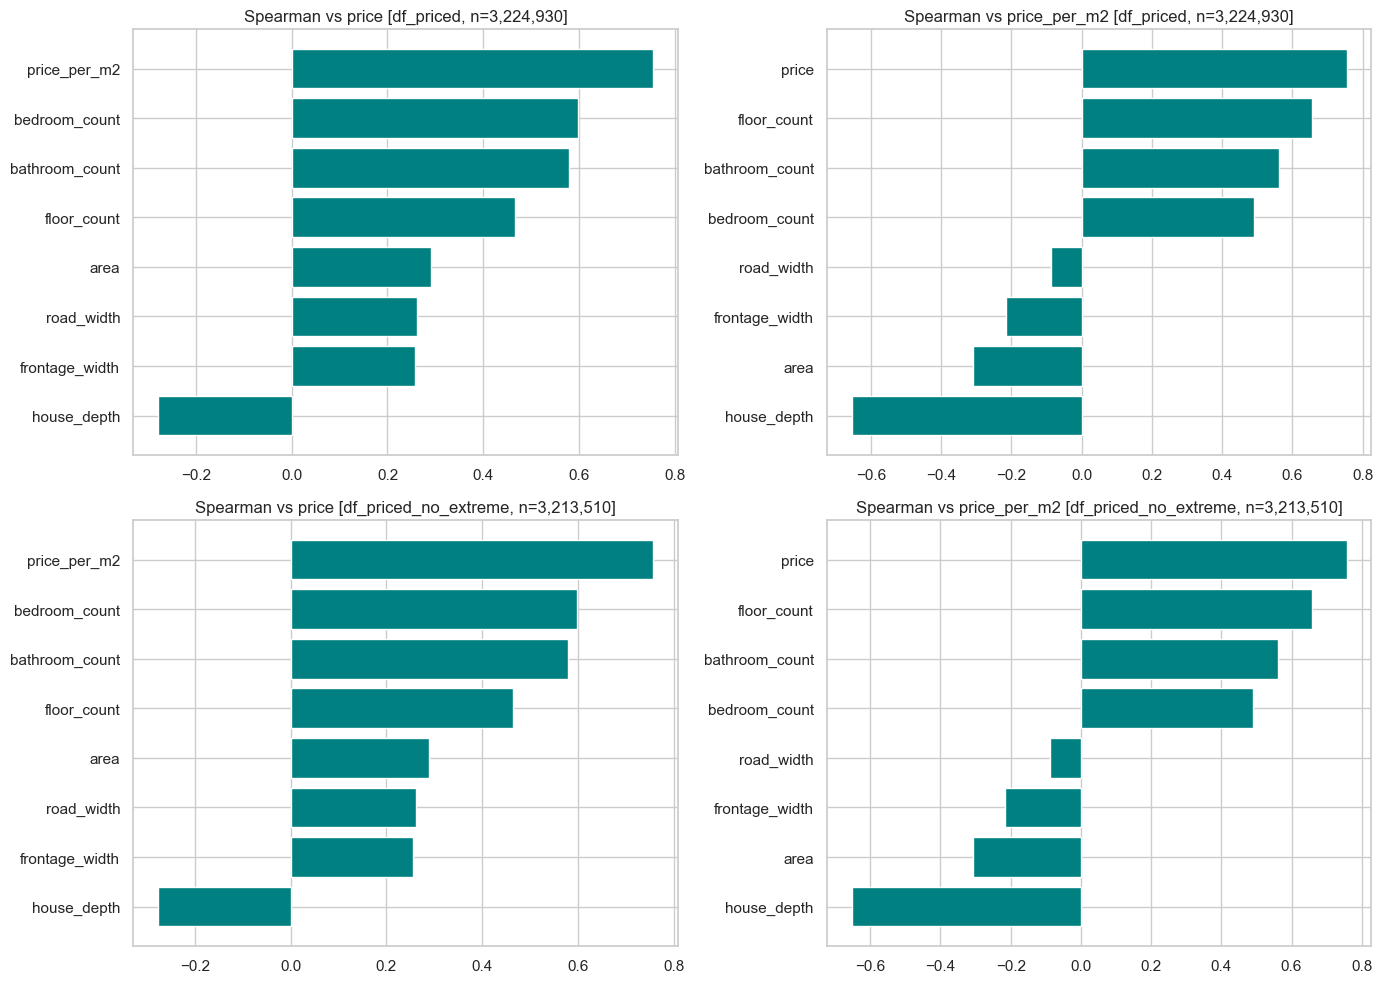

In [78]:
def ranked_spearman_bars(spearman_mat, target, ax, frame_name, n):
    s = spearman_mat[target].drop(labels=[target]).dropna().sort_values()
    ax.barh(s.index.astype(str), s.values, color="teal")
    ax.set_title(title_with_n(f"Spearman vs {target}", frame_name, n))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ranked_spearman_bars(spearman1, "price", axes[0, 0], "df_priced", len(df_priced))
ranked_spearman_bars(spearman1, "price_per_m2", axes[0, 1], "df_priced", len(df_priced))
ranked_spearman_bars(spearman2, "price", axes[1, 0], "df_priced_no_extreme", len(df_priced_no_ext))
ranked_spearman_bars(spearman2, "price_per_m2", axes[1, 1], "df_priced_no_extreme", len(df_priced_no_ext))
plt.tight_layout()
plt.show()


In [79]:
log_frame = df_priced.copy()
for c in ["price", "area", "price_per_m2"]:
    log_frame[f"log10_{c}"] = np.log10(log_frame[c].where(log_frame[c] > 0))
log_cols = ["log10_price", "log10_area", "log10_price_per_m2"] + [
    c for c in CORR_COLS if c not in {"price", "area", "price_per_m2"}
]
pearson_log, n_log = pairwise_corr(log_frame, log_cols, method="pearson")
print(title_with_n("Pearson with log10(price, area, price_per_m2)", "df_priced", len(df_priced)))
display(pearson_log)
display(n_log.astype(int))


Pearson with log10(price, area, price_per_m2) [df_priced, n=3,224,930]


,log10_price,log10_area,log10_price_per_m2,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count
log10_price,1.000000,0.311071,0.715447,0.410976,-0.000999,-0.015490,0.038197,0.383737,0.399257
log10_area,0.311071,1.000000,-0.441449,-0.079373,0.000591,0.224908,0.058808,0.182498,0.130574
log10_price_per_m2,0.715447,-0.441449,1.000000,0.567817,-0.001313,-0.148035,-0.012875,0.281652,0.338866
floor_count,0.410976,-0.079373,0.567817,1.000000,0.001654,-0.131996,0.005937,0.401216,0.456148
frontage_width,-0.000999,0.000591,-0.001313,0.001654,1.000000,0.033705,0.000546,-0.000097,-0.000158
house_depth,-0.015490,0.224908,-0.148035,-0.131996,0.033705,1.000000,NaN,0.037736,0.012887
road_width,0.038197,0.058808,-0.012875,0.005937,0.000546,NaN,1.000000,0.010276,0.011604
bedroom_count,0.383737,0.182498,0.281652,0.401216,-0.000097,0.037736,0.010276,1.000000,0.948003
bathroom_count,0.399257,0.130574,0.338866,0.456148,-0.000158,0.012887,0.011604,0.948003,1.000000


,log10_price,log10_area,log10_price_per_m2,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count
log10_price,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
log10_area,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
log10_price_per_m2,3224930,3224930,3224930,742742,1662052,59487,614511,1749076,1636582
floor_count,742742,742742,742742,742742,517653,17799,358196,594050,548209
frontage_width,1662052,1662052,1662052,517653,1662052,59469,548138,790254,746294
house_depth,59487,59487,59487,17799,59469,59487,210,17264,13504
road_width,614511,614511,614511,358196,548138,210,614511,347100,330043
bedroom_count,1749076,1749076,1749076,594050,790254,17264,347100,1749076,1602003
bathroom_count,1636582,1636582,1636582,548209,746294,13504,330043,1602003,1636582


### 2.7. Anomaly investigation and duplicate sensitivity


In [80]:
flag_cols = [c for c in df_clean.columns if c.startswith("flag_")]
print(title_with_n("Extreme / validity flag counts", "df_clean", len(df_clean)))
display(df_clean[flag_cols].sum().rename("count").to_frame())
print("flag_extreme_price_per_m2 on df_priced:", int(df_priced["flag_extreme_price_per_m2"].sum()))


Extreme / validity flag counts [df_clean, n=3,500,744]


,count
flag_nonpositive_price,57320
flag_nonpositive_area,0
flag_negative_floor_count,0
flag_negative_bedroom_count,0
flag_negative_bathroom_count,0
flag_extreme_area,3500
flag_extreme_floor_count,651
flag_extreme_bedroom_count,1799
flag_extreme_bathroom_count,1742


flag_extreme_price_per_m2 on df_priced: 6400


In [81]:
print(title_with_n("10 largest soft-duplicate clusters", "df_clean", len(df_clean)))
display(soft_clusters.rename("cluster_size").to_frame())

ext_any = df_priced[extreme_flags].any(axis=1)
suspicious = df_priced.loc[ext_any].sample(
    n=min(10, int(ext_any.sum())), random_state=RANDOM_STATE
)
print(title_with_n("10 suspicious records with any flag_extreme_*", "df_priced", len(df_priced)))
display(suspicious[
    ["name", "province_name", "property_type_name", "price", "area", "price_per_m2"]
    + extreme_flags
])


10 largest soft-duplicate clusters [df_clean, n=3,500,744]


,cluster_size
14133054121955044176,121
13396537198429708950,81
16691324701128384324,79
9646511522010444815,75
9456638442733968437,68
17208016835494765349,68
191791319593057052,67
15682930743098231210,66
14118773797077778614,62
11354715444241774349,60


10 suspicious records with any flag_extreme_* [df_priced, n=3,224,930]


,name,province_name,property_type_name,price,area,price_per_m2,flag_extreme_area,flag_extreme_floor_count,flag_extreme_bedroom_count,flag_extreme_bathroom_count,flag_extreme_price_per_m2
3399301,"Bán CC ÂU CƠ TOWER DT 75M2,2PN NTCB GIÁ 10TR/T...",Hồ Chí Minh,Căn hộ chung cư,1.000000e+07,75.0,1.333333e+05,False,False,False,False,True
2055831,"Bán tòa căn hộ phố Trích Sài, Võng Thị, Tây Hồ...",Hà Nội,Nhà,9.300000e+10,280.0,3.321429e+08,False,False,True,True,False
1326728,"Bán đất tại Ninh Tân, Ninh Hòa, Khánh Hòa, 110...",Khánh Hòa,Đất,3.010524e+10,273684.0,1.100000e+05,True,False,False,False,True
288256,Đại Đô Thị Đông Tiến - Giá Cực Rẻ Chỉ Từ 850tr/lô,Thanh Hóa,Đất,8.500000e+11,100000.0,8.500000e+06,True,False,False,False,False
1235756,"Bán 2 mẫu 9 đất khu dân cư, vườn trái cây, giá...",Bà Rịa - Vũng Tàu,Đất,2.900000e+10,29000.0,1.000000e+06,True,False,False,False,False
2203215,Bán nhà biệt thự 2 mặt tiền 86 Võ Văn Tần - 10...,Hồ Chí Minh,Biệt thự/Nhà liền kề,8.100000e+11,600.9,1.347978e+09,False,False,False,False,True
481668,Lô góc hai thoáng các phòng đều có ban công PC...,Hà Nội,Nhà,4.000000e+10,153.0,2.614379e+08,False,False,True,True,False
3449860,"Quỹ đất 26,041m2 (2.6ha) Số 481 Xa Lộ Hà Nội (...",Hồ Chí Minh,Đất,9.680000e+11,26041.0,3.717215e+07,True,False,False,False,False
3222138,"Quỹ Đất PTDA 5.1ha Trần Não & Mai Chí Thọ, Q2 ...",Hồ Chí Minh,Đất,7.140000e+12,51000.0,1.400000e+08,True,False,False,False,False
597518,"Đất Bình Phước siêu hot, diện tích 40000m2, có...",Bình Phước,Đất,7.800000e+08,40000.0,1.950000e+04,True,False,False,False,True


In [82]:
def summarize_priced(frame):
    return pd.Series({
        "n": len(frame),
        "median_price": frame["price"].median(),
        "median_area": frame["area"].median(),
        "median_price_per_m2": frame["price_per_m2"].median(),
    })

all_rows = summarize_priced(df_priced)
no_soft = summarize_priced(df_priced.loc[~df_priced["is_soft_dup"]])
sens = pd.DataFrame({"df_priced": all_rows, "no_soft_dup": no_soft})
sens["abs_diff"] = sens["no_soft_dup"] - sens["df_priced"]
sens["pct_diff"] = sens["abs_diff"] / sens["df_priced"]
print(title_with_n("Duplicate sensitivity (overall)", "df_priced", len(df_priced)))
display(sens)

rows = []
for prov in df_priced["province_name"].value_counts().head(10).index:
    a = summarize_priced(df_priced[df_priced["province_name"] == prov])
    b = summarize_priced(
        df_priced[(df_priced["province_name"] == prov) & ~df_priced["is_soft_dup"]]
    )
    rows.append({
        "province_name": prov,
        "n": a["n"],
        "n_no_soft": b["n"],
        "median_price": a["median_price"],
        "median_price_no_soft": b["median_price"],
        "median_ppm2": a["median_price_per_m2"],
        "median_ppm2_no_soft": b["median_price_per_m2"],
        "price_pct_diff": (b["median_price"] - a["median_price"]) / a["median_price"],
        "ppm2_pct_diff": (b["median_price_per_m2"] - a["median_price_per_m2"]) / a["median_price_per_m2"],
    })
print(title_with_n("Duplicate sensitivity (top 10 provinces)", "df_priced", len(df_priced)))
display(pd.DataFrame(rows))


Duplicate sensitivity (overall) [df_priced, n=3,224,930]


,df_priced,no_soft_dup,abs_diff,pct_diff
n,3.224930e+06,2.415372e+06,-8.095580e+05,-0.251031
median_price,7.500000e+09,7.400000e+09,-1.000000e+08,-0.013333
median_area,8.000000e+01,8.000000e+01,0.000000e+00,0.000000
median_price_per_m2,9.777778e+07,9.459459e+07,-3.183183e+06,-0.032555


Duplicate sensitivity (top 10 provinces) [df_priced, n=3,224,930]


,province_name,n,n_no_soft,median_price,median_price_no_soft,median_ppm2,median_ppm2_no_soft,price_pct_diff,ppm2_pct_diff
0,Hồ Chí Minh,1279090.0,933849.0,7.700000e+09,7.700000e+09,1.087912e+08,1.059172e+08,0.000000,-0.026418
1,Hà Nội,1035822.0,782926.0,9.620000e+09,9.500000e+09,1.875000e+08,1.833333e+08,-0.012474,-0.022222
2,Đà Nẵng,167878.0,125381.0,8.000000e+09,8.000000e+09,7.850000e+07,7.928571e+07,0.000000,0.010009
3,Bình Dương,138995.0,104586.0,2.915000e+09,2.870000e+09,3.757022e+07,3.723404e+07,-0.015437,-0.008948
4,Khánh Hòa,94320.0,70133.0,4.900000e+09,5.090000e+09,5.389831e+07,5.446429e+07,0.038776,0.010501
5,Hải Phòng,66179.0,50103.0,3.850000e+09,3.900000e+09,5.072464e+07,5.052083e+07,0.012987,-0.004018
6,Hưng Yên,57181.0,45679.0,7.600000e+09,7.600000e+09,8.459870e+07,8.500000e+07,0.000000,0.004744
7,Đồng Nai,55053.0,40578.0,2.750000e+09,2.680000e+09,2.055556e+07,2.000000e+07,-0.025455,-0.027027
8,Bà Rịa - Vũng Tàu,43941.0,35292.0,3.950000e+09,3.600000e+09,2.550000e+07,2.347546e+07,-0.088608,-0.079394
9,Long An,42963.0,33694.0,2.200000e+09,2.200000e+09,2.109375e+07,2.157519e+07,0.000000,0.022824


### 2.8. Key findings and summary

Exactly six evidence-based insights. Wording is associational; prices are asking prices.


In [83]:
n_clean = len(df_clean)
n_priced = len(df_priced)

prov_ppm2_tbl = group_median_table(df_priced, "province_name", "price_per_m2", min_n=100)
top_prov_row = prov_ppm2_tbl.sort_values("median", ascending=False).iloc[0]
bot_prov_row = prov_ppm2_tbl.sort_values("median", ascending=True).iloc[0]

type_ppm2_tbl = group_median_table(df_priced, "property_type_name", "price_per_m2", min_n=100)
top_type_row = type_ppm2_tbl.sort_values("median", ascending=False).iloc[0]

sp_area = spearman1.loc["area", "price"]
sp_n = int(n1.loc["area", "price"])

soft_share_priced = float(df_priced["is_soft_dup"].mean())
med_price = float(df_priced["price"].median())
med_ppm2 = float(df_priced["price_per_m2"].median())
priced_share = n_priced / n_clean

insights = [
    f"1. Under the sale-market assumption, df_priced keeps {priced_share:.1%} of df_clean (n_priced={n_priced:,} of n_clean={n_clean:,}) after requiring positive price and area.",
    f"2. Among df_priced (n={n_priced:,}), median asking price is {med_price:,.0f} VND and median asking price_per_m2 is {med_ppm2:,.0f} VND/m².",
    f"3. Median asking price_per_m2 is higher in {top_prov_row['province_name']} ({top_prov_row['median']:,.0f} VND/m², n={int(top_prov_row['n']):,}) than in {bot_prov_row['province_name']} ({bot_prov_row['median']:,.0f} VND/m², n={int(bot_prov_row['n']):,}) among provinces with n≥100.",
    f"4. Median asking price_per_m2 is higher for property type {top_type_row['property_type_name']} ({top_type_row['median']:,.0f} VND/m², n={int(top_type_row['n']):,}) than for other types with n≥100 in df_priced.",
    f"5. Area is associated with asking price (Spearman={sp_area:.3f}, pairwise n={sp_n:,}) on df_priced.",
    f"6. Soft-duplicate rows are {soft_share_priced:.1%} of df_priced (n={n_priced:,}); removing them changes overall medians as shown in the duplicate-sensitivity table.",
]
for line in insights:
    print(line)
assert len(insights) == 6


1. Under the sale-market assumption, df_priced keeps 92.1% of df_clean (n_priced=3,224,930 of n_clean=3,500,744) after requiring positive price and area.
2. Among df_priced (n=3,224,930), median asking price is 7,500,000,000 VND and median asking price_per_m2 is 97,777,778 VND/m².
3. Median asking price_per_m2 is higher in Hà Nội (187,500,000 VND/m², n=1,035,822) than in Đắk Nông (1,006,977 VND/m², n=900) among provinces with n≥100.
4. Median asking price_per_m2 is higher for property type Nhà (162,962,963 VND/m², n=1,493,988) than for other types with n≥100 in df_priced.
5. Area is associated with asking price (Spearman=0.290, pairwise n=3,224,930) on df_priced.
6. Soft-duplicate rows are 25.1% of df_priced (n=3,224,930); removing them changes overall medians as shown in the duplicate-sensitivity table.


### Final invariant checks


In [84]:
assert df_clean.index.equals(df.index)
assert len(df_clean) == len(df)
assert df_priced.index.isin(df_clean.index).all()
assert (df_priced["price"] > 0).all()
assert (df_priced["area"] > 0).all()
assert "price_per_m2" in df_priced.columns
assert "price_per_m2" not in df_clean.columns
assert "transaction_type" not in df_clean.columns
print("All invariants passed.")
print(f"df_priced n={n_priced:,} ({n_priced / n_clean:.2%} of df_clean)")


All invariants passed.
df_priced n=3,224,930 (92.12% of df_clean)
